# Figure 3 as a phase-recovery design loop

Paraphrase of the idea in B. Jalali, A. Kadambi, V. Roychowdhury, *Physics-AI Symbiosis*, arXiv:2109.05959, Fig. 3
(no text or figure reproduced). Plan: **SymPy** for the exact algebra, **SciPy** for a lumped-circuit
time-invariant check, **Torch** for the learned-illumination loop.

A camera sees only intensity, $I = t\,t^{*} = |t|^2$ (field times its complex conjugate, the bra-ket $\langle t|t\rangle$).
Phase has to be recovered.

In [1]:
import sys, pathlib
_root = pathlib.Path.cwd()
_root = _root.parent if (_root.parent / 'dgs').is_dir() else _root   # works from notebooks/ or repo root
sys.path.insert(0, str(_root))
import numpy as np, sympy as sp, matplotlib.pyplot as plt
import scipy.signal as sig, scipy.fft as sfft
sp.init_printing(use_latex='mathjax')

## 1. SymPy: intensity throws phase away, dispersion turns frequency into time

In [2]:
w, b2, L, phi0 = sp.symbols('omega beta_2 L phi_0', real=True)
t = sp.Function('t')
A, phi = sp.symbols('A phi', real=True)
field = A*sp.exp(sp.I*phi)
intensity = sp.simplify(field*sp.conjugate(field))
display(sp.Eq(sp.Symbol('I'), intensity))      # phi is gone: one frame cannot give phase

# time-stretch: a dispersive medium multiplies the spectrum by exp(i*beta2*L*omega^2/2)
phase = b2*L*w**2/2
tau = sp.diff(phase, w)                        # group delay = d(phase)/d(omega)
display(sp.Eq(sp.Symbol('tau_g'), tau))        # delay grows linearly with frequency -> wavelength-to-time map

     2
I = A 

τ_g = L⋅β₂⋅ω

## 2. SciPy: a lumped RC circuit is linear and time-invariant, so magnitude fixes phase

RC low-pass $H(s)=1/(1+sRC)$ is minimum phase. For such a system the log-magnitude determines the phase
(Kramers-Kronig / cepstral method), so phase retrieval is easy; it fails for non-minimum-phase systems.

max phase error from magnitude alone (|w|<10wc): 0.0119 rad


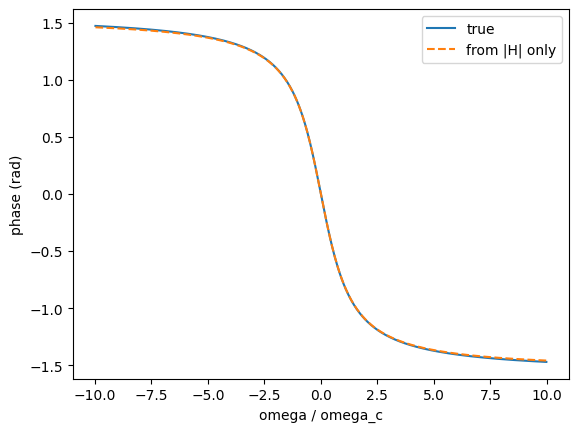

In [3]:
R, C = 1e3, 1e-9
wc = 1/(R*C)
N = 2**16
# the grid must reach far past the corner: log|H| of an RC filter decays only logarithmically, so a
# narrow grid (40 wc) aliases the cepstrum and leaves a 0.6 rad error; 2000 wc gives ~0.01 rad
f = sfft.fftfreq(N, d=1/(2000*wc/(2*np.pi)))
om = 2*np.pi*f
H = 1/(1 + 1j*om*R*C)
# cepstral minimum-phase reconstruction from |H| only
logmag = np.log(np.abs(H))
cep = sfft.ifft(logmag).real
fold = np.zeros(N); fold[0] = cep[0]; fold[1:N//2] = 2*cep[1:N//2]; fold[N//2] = cep[N//2]
phase_est = sfft.fft(fold).imag
true_phase = np.angle(H)
k = np.abs(om) < 10*wc
err = np.max(np.abs(phase_est[k] - true_phase[k]))
print('max phase error from magnitude alone (|w|<10wc): %.4f rad' % err)
sel = np.argsort(om)
plt.plot(om[sel][k[sel]]/wc, true_phase[sel][k[sel]], label='true')
plt.plot(om[sel][k[sel]]/wc, phase_est[sel][k[sel]], '--', label='from |H| only')
plt.xlabel('omega / omega_c'); plt.ylabel('phase (rad)'); plt.legend(); plt.show()
assert err < 0.05

## 3. Distributed vs lumped: the transfer-matrix check (links to `dgs/metasurface_surrogate.py`)

A slab's SymPy Airy formula must equal the numeric transfer-matrix solver.

In [4]:
from dgs import metasurface_surrogate as ms
n, d, lam = sp.symbols('n d lambda', positive=True)
r12 = (1-n)/(1+n)
delta = 2*sp.pi*n*d/lam
T_sym = (1-r12**2)**2/(1-2*r12**2*sp.cos(2*delta)+r12**4)
f_T = sp.lambdify((n,d,lam), T_sym, 'numpy')
wl = np.linspace(500, 900, 40)
gap = np.max(np.abs(f_T(2.0, 150.0, wl) - ms.transmission([150.0], wl, n_layers=[2.0])))
print('symbolic vs numeric max gap:', gap); assert gap < 1e-10

symbolic vs numeric max gap: 4.440892098500626e-16


## 4. Torch: learn the illumination (the loop in Fig. 3, panel c)

Masks are trained by autograd through an unrolled Gerchberg-Saxton reconstruction under a fixed power budget.
Scored at only 20 iterations, so this mostly shows **faster convergence**, not new recoverability.

held-out fidelity  random: 0.100   learned: 0.319


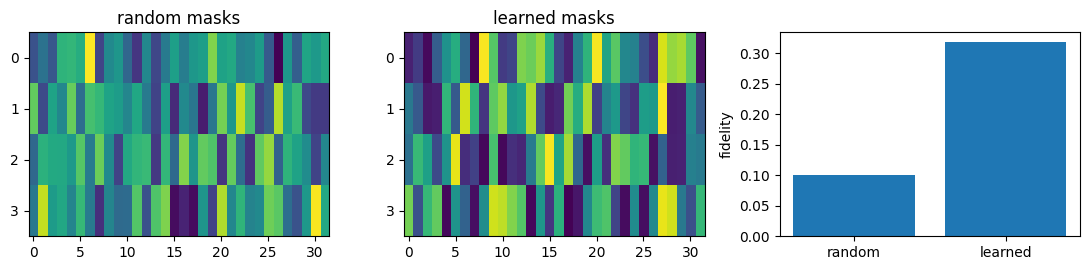

In [5]:
from dgs import coded_illumination_design as cid
r = cid.train_masks(K=4, seed=0, steps=150)
print('held-out fidelity  random: %.3f   learned: %.3f' % (r['fid_random'], r['fid_learned']))
fig, ax = plt.subplots(1, 3, figsize=(11, 2.8))
ax[0].imshow(r['random'], aspect='auto'); ax[0].set_title('random masks')
ax[1].imshow(r['learned'], aspect='auto'); ax[1].set_title('learned masks')
ax[2].bar(['random','learned'], [r['fid_random'], r['fid_learned']]); ax[2].set_ylabel('fidelity')
plt.tight_layout(); plt.show()
assert r['fid_learned'] > 2*r['fid_random']

## 5. Previous design to updated design (Fig. 3, panel c)

The same training run, snapshotted: step 0 is the *previous design* (random masks), later steps are *updated designs*
after gradient updates. Each row is one illumination pattern across the 32 pixels.

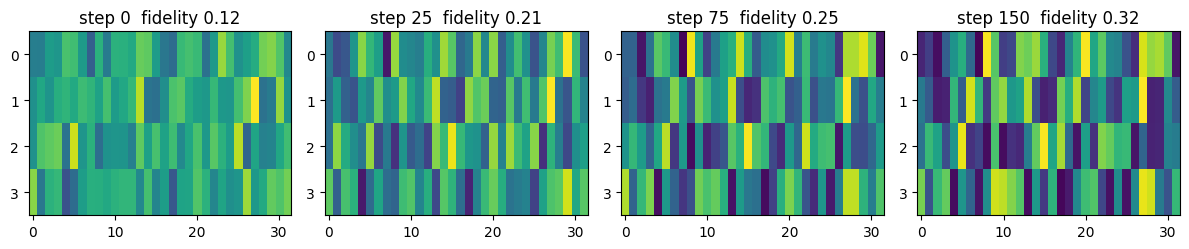

fidelity by step: [0.122, 0.208, 0.25, 0.319]


In [6]:
steps_show = [0, 25, 75, 150]
snap = cid.train_masks(K=4, seed=0, steps=150, snap_at=steps_show)['snapshots']
fig, ax = plt.subplots(1, 4, figsize=(12, 2.6))
for a, s in zip(ax, steps_show):
    m, fid = snap[s]
    a.imshow(m, aspect='auto', vmin=0, vmax=m.max()); a.set_title('step %d  fidelity %.2f' % (s, fid))
plt.tight_layout(); plt.show()
fids = [snap[s][1] for s in steps_show]
print('fidelity by step:', [round(f, 3) for f in fids])
assert fids[-1] > fids[0] + 0.1

## 6. Projectile motion rederived (the PhysicsNAS example)

SymPy derives the vacuum trajectory, the 45 degree optimum, and the effect of linear drag. (A note on the Iron
Dome idea: its interceptors are kinetic missiles, i.e. exactly this physics plus guidance; the laser-based
system in that family is a separate one. Neither needs the photonics maths above except for sensing.)

In [7]:
t, v0, th, g, k = sp.symbols('t v_0 theta g k', positive=True)
x = v0*sp.cos(th)*t
y = v0*sp.sin(th)*t - g*t**2/2
t_land = sp.solve(sp.Eq(y, 0), t)
t_land = [s for s in t_land if s != 0][0]
R = sp.simplify(x.subs(t, t_land))
display(sp.Eq(sp.Symbol('R'), sp.simplify(R)))
best = sp.solve(sp.diff(R, th), th)
print('optimal launch angle(s):', best)

# vertical motion with linear drag: dv/dt = -g - k v
v = sp.Function('v')
sol = sp.dsolve(sp.Eq(v(t).diff(t), -g - k*v(t)), v(t), ics={v(0): v0})
display(sol)
vac = sp.limit(sol.rhs, k, 0)
print('k -> 0 recovers vacuum v0 - g t:', sp.simplify(vac - (v0 - g*t)) == 0)
print('terminal velocity:', sp.limit(sol.rhs, t, sp.oo))
assert sp.simplify(vac - (v0 - g*t)) == 0
assert sp.pi/4 in best

      2         
    v₀ ⋅sin(2⋅θ)
R = ────────────
         g      

optimal launch angle(s): [pi/4, 3*pi/4]


                         -k⋅t
         g   (g + k⋅v₀)⋅ℯ    
v(t) = - ─ + ────────────────
         k          k        

k -> 0 recovers vacuum v0 - g t: True
terminal velocity: -g/k


## 7. Black-body radiation checked numerically (radiaci\u00f3n de cuerpo negro)

Planck's law, Wien's displacement constant from a root-find, and the Stefan-Boltzmann constant from numerical
integration of Planck's law, all against SciPy's tabulated constants.

In [8]:
from scipy import constants as K_, optimize, integrate
h, c, kB, sigma = K_.h, K_.c, K_.k, K_.sigma
# Wien: with x = hc/(lambda kB T), maximum of Planck per wavelength satisfies (x-5) e^x + 5 = 0
xw = optimize.brentq(lambda x: (x-5)*np.exp(x)+5, 1, 10)
b = h*c/(xw*kB)
print('Wien constant: %.6e m K  (tabulated %.6e)' % (b, K_.Wien))
# Stefan-Boltzmann: sigma T^4 = pi * integral of B_lambda dlambda
T = 5772.0
B = lambda lam: 2*h*c**2/lam**5/(np.exp(h*c/(lam*kB*T))-1)
I, _ = integrate.quad(B, 1e-8, 1e-3, points=[b/T], limit=200)
print('pi*integral / T^4 = %.6e  (sigma = %.6e)' % (np.pi*I/T**4, sigma))
assert abs(b - K_.Wien)/K_.Wien < 1e-6
assert abs(np.pi*I/T**4 - sigma)/sigma < 1e-3

Wien constant: 2.897772e-03 m K  (tabulated 2.897772e-03)
pi*integral / T^4 = 5.670374e-08  (sigma = 5.670374e-08)


### Glosario ingl\u00e9s - espa\u00f1ol

| English | Espa\u00f1ol |
|---|---|
| phase retrieval | recuperaci\u00f3n de fase |
| intensity | intensidad |
| complex conjugate | conjugado complejo |
| group delay | retardo de grupo |
| dispersion | dispersi\u00f3n |
| transmission | transmisi\u00f3n |
| radiation | radiaci\u00f3n |
| black-body radiation | radiaci\u00f3n de cuerpo negro |
| electric / magnetic field | campo el\u00e9ctrico / magn\u00e9tico |
| wavelength | longitud de onda |
| projectile motion | tiro parab\u00f3lico (movimiento de proyectiles) |
| neural network | red neuronal |
| illumination pattern | patr\u00f3n de iluminaci\u00f3n |
| design update (gradient step) | actualizaci\u00f3n del dise\u00f1o (paso de gradiente) |

## Takeaways
- Intensity is $t\,t^*$; the phase symbol disappears (section 1).
- Lumped LTI circuits: magnitude fixes phase when minimum phase (section 2); near THz use distributed models (section 3).
- Illumination is a trainable design variable (section 4); the honest caveat is in `docs/figure3_coded_illumination.md`.